# Lab 09: How to choose between a chain, a router and an agent

**CPU | API key: `OPENAI_API_KEY` (Part A runs without one) | Follows: Day 2 D2-M04, steps 4.1 to 4.7 (slides 89–125)**

Until now the copilot has been one agent: it holds every tool and the model decides each next step. Many support jobs
do not need that freedom. Some always run the same steps in the same order; some only need to be sent to the right
specialist. In this lab you build those two fixed paths, a **chain** and a **router**, as LangGraph graphs, run the
same five rep requests through the router and through the copilot agent, and count what each one costs and gets right.

## Goal

Choose the shape for a job from measurements: build a chain and a router in LangGraph, run the same requests through
the router and the agent, and compare their model calls, tokens, seconds and outcomes. The moment that teaches it:
request 5 asks for a policy and an order count. It was labelled `policy_question` in 3 of 3 runs, and the policy handler, which has no customer tool, searched the handbook 12 to 34 times for the count and never gave it: 13 to 35 model calls and 97,000 input tokens on average, where the agent answered both parts in 3 or 4 calls and about 4,100 tokens (`gpt-4o-mini`, 12 Oct 2026).

## What you will learn

- How to write a fixed sequence of steps as plain function calls, then as a LangGraph `StateGraph` with typed state,
  nodes and edges, and how to read the graph's structure and each step's update.
- How to find a chain's missing step by checking its output against the rule in code, and add the step.
- How to label a request with `with_structured_output` and a `Literal`, route on the label with an `if` and then a
  conditional edge, and test the labels against your own over several runs.
- How to put agents behind a router, each with only its tools, and resume a paused handler on the router's thread.
- How to measure model calls, tokens and seconds per request for a router and an agent, and how to split a request
  with two needs and send each part to its own handler with `Send`.
- How to choose a chain, a router or an agent for a job by asking who decides the next step, with evidence.

| Part | What you do | Calls to OpenAI |
|---|---|---|
| A | Write ticket 14's chain as three functions, then as a graph; read its structure and each step's update | 0 (scripted stand-in models) |
| B | Run the chain on ticket 14, check the note against the refund rule, add the missing step | about 14 |
| C | Label five requests, route on the label, then build the router graph | about 37 |
| D | Put three agents behind the router; pause and resume the refund; run the other requests | about 30 |
| E | Run the five requests three times through the router and through the agent, and compare | about 140 |
| F | Split a request into its parts and send each part to its handler | about 50 |
| G | Choose a shape for five support jobs | 0 |
| H (optional) | Load two tools from an MCP server | about 4 |

About 270 calls to `CHAT_MODEL` in all in our run, with about 440,000 input tokens, two thirds of them from the router's three runs of request 5 in Part E: under 10 US cents with `gpt-4o-mini`. Each handbook search adds an embedding call of a few tokens.

## The first two cells

These are the same two cells that open Lab 00, which explains each line. **Setup** finds the repository folder (on
Colab it copies the repository and installs the packages first). **Config** reads the model names from `models.env`
and finds your key without printing it.

In [1]:
# Setup: on Colab, copy the repository and install the packages. Locally (after uv sync) nothing is installed.
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/agentic_ai_conversational_agents").exists():
        !git clone -q --depth 1 https://github.com/tatwan/agentic_ai_conversational_agents.git /content/agentic_ai_conversational_agents
    %cd /content/agentic_ai_conversational_agents
    %pip install -q -r requirements.txt

ROOT = next(folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / "models.env").exists())
sys.path.insert(0, str(ROOT))
print("Repository folder:", ROOT.name)

Repository folder: agentic_ai_conversational_agents


⚠️ On Colab, run the setup cell first in a fresh session. If another cell loaded the old `openai` package before the
install, the first model call fails with `ImportError: cannot import name ... from 'openai...'`; use **Runtime →
Restart session** and run from the top.

In [2]:
# Config: model names come from models.env; the key from the environment, .env or Colab Secrets.
from shared.settings import load_settings, load_key

settings = load_settings()
key_found_in = load_key("OPENAI_API_KEY")

for name in ("CHAT_MODEL", "REASONING_EFFORT", "JUDGE_MODEL", "EMBED_MODEL"):
    print(f"{name:18}{settings[name] or '(not set)'}")
print(f"{'OPENAI_API_KEY':18}{'found in ' + key_found_in if key_found_in else 'not found'}")

CHAT_MODEL        gpt-4o-mini
REASONING_EFFORT  (not set)
JUDGE_MODEL       gpt-4o-mini
EMBED_MODEL       text-embedding-3-small
OPENAI_API_KEY    found in .env


Parts B to F call `CHAT_MODEL`; every handbook search embeds its query with `EMBED_MODEL`.

The picture shows the three shapes this lab compares, by who decides the next step. In the **chain** your code fixes
every step and its order; dark boxes call a model, light ones are plain code. In the **router** the model chooses one
label and your code maps the label to a path; one path needs no model at all. In the **agent** the model chooses every
next step: which tool, how often, and when to stop.

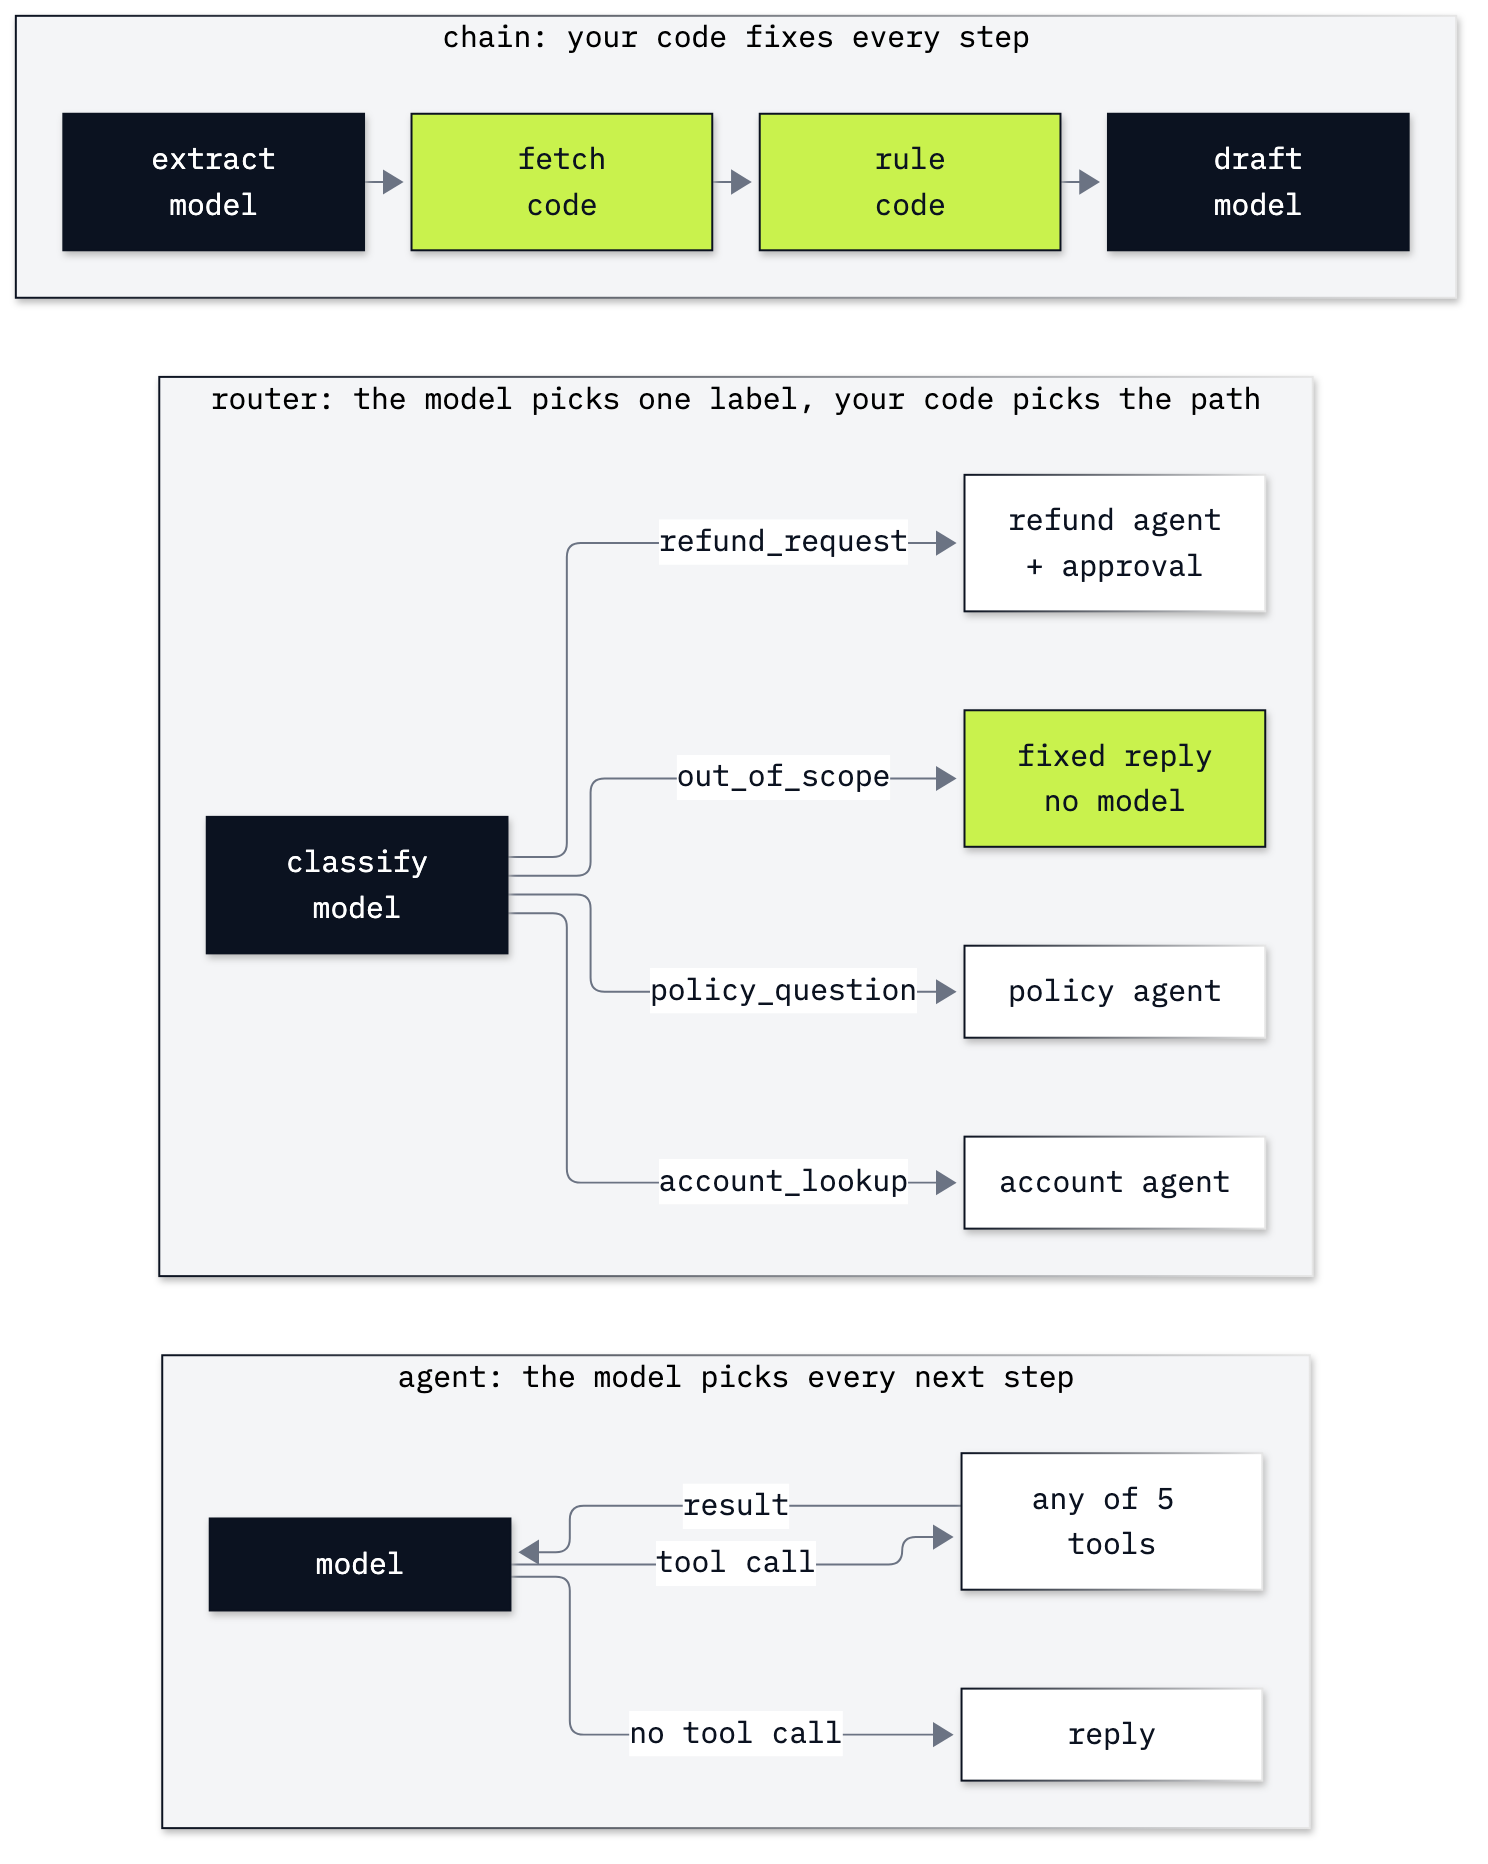

In [3]:
from IPython.display import Image
Image(filename=ROOT / "09_Chain_And_Router" / "resources" / "lab09_three_shapes.png", width=620)

---

## Start the Ops API and load the copilot's tools

The copilot acts through the **Ops API**, the small HTTP service you started in Lab 00 Part D. Start it in this
notebook; it runs in a background thread until you stop it at the end.

In [4]:
from shared.ops_api import start_ops_api

server = start_ops_api()

Ops API started at http://127.0.0.1:8765


These are the tools from Labs 06 to 08, kept in `shared/ops_tools.py`: four that read and one that writes. The agent
gets all five; each handler behind the router gets only the ones its job needs.

In [5]:
from shared.ops_tools import READ_TOOLS, WRITE_TOOLS, RepContext, copilot_prompt

for t in READ_TOOLS + WRITE_TOOLS:
    kind = "writes" if t in WRITE_TOOLS else "reads"
    print(f"{kind:7}{t.name:23}{t.description.splitlines()[0]}")

reads  search_policies        Return the three handbook passages closest to a query. Call it before answering any question about shop rules.
reads  find_customer          Find customers by name: id, name, country and rep.
reads  get_customer_invoices  List one customer's invoices, with count, total and rep.
reads  get_invoice            Return one invoice: date, total, customer and albums.
writes file_refund_request    File a refund request. A person reviews it first. Use it only after the policy and the invoice show a refund


---

## Part A: Write a chain as a graph

A **chain** (prompt chaining) splits a task into steps that always run in the same order, each working on the output
of the one before. A step can call a model or be plain code. This part writes ticket 14's chain twice: as three
Python functions called one after another, then as a LangGraph graph, so you can see what the graph adds. Nothing
here calls OpenAI.

### Three steps as plain functions

Ticket 14 is the duplicate charge you met in Lab 08. The chain turns it into a note for the rep in three steps:

1. **extract**: a model reads the ticket and returns the invoice numbers as typed data;
2. **fetch**: plain code asks the Ops API for each invoice (no model, no tokens, the same result every time);
3. **draft**: a model writes a two-sentence note from the fetched facts.

The schema for step 1 is a Pydantic class, as in Lab 02 Part D: the model must return a list of whole numbers.

In [6]:
import json
from pydantic import BaseModel, Field

class Invoices(BaseModel):
    invoice_ids: list[int] = Field(description="Invoice numbers in the ticket, digits only.")

TICKET_14 = ("Ticket 14: two charges of 9.99 for The Essential Miles Davis on 2013-11-02. "
             "The customer attached invoice numbers 9001 and 9002.")

For the shape of the chain, the model's words do not matter, so Part A uses a **scripted model**
(`shared/scripted.py`, labelled SCRIPTED MODEL · NO API CALL): it returns messages written in advance. `reader`
answers step 1 with invoices 9001 and 9002; `writer` answers step 3 with a placeholder note. Part B swaps in the real
model.

In [7]:
from langchain_core.messages import AIMessage
from shared.scripted import scripted, call

# SCRIPTED MODEL · NO API CALL
reader = scripted(call("Invoices", {"invoice_ids": [9001, 9002]})).with_structured_output(Invoices)
writer = scripted(AIMessage("(scripted note for the rep)"))

The three steps are ordinary functions. `_get` is the Ops API helper from Lab 07: it returns the API's answer as JSON
text. Read the comments: two steps call a model, one does not.

In [8]:
from shared.ops_tools import _get

def extract(ticket):                       # 1: a model reads the ticket
    return reader.invoke(ticket).invoice_ids

def fetch(invoice_ids):                    # 2: plain code calls the Ops API, no model
    return [json.loads(_get(f"/invoices/{i}")) for i in invoice_ids]

def draft(ticket, invoices):               # 3: a model writes the note from the facts
    prompt = f"Draft a two-sentence note for the rep.\nTicket: {ticket}\nInvoices: {json.dumps(invoices)}"
    return writer.invoke(prompt).text

Call them in order, each with the output of the one before. That is the whole chain.

In [9]:
ids = extract(TICKET_14)
invoices = fetch(ids)
note = draft(TICKET_14, invoices)

print("invoice ids:", ids)
for invoice in invoices:
    print(invoice["invoice_id"], invoice["date"], invoice["total"], invoice["source"])
print("note:", note)

invoice ids: [9001, 9002]
9001 2013-11-02 9.99 course fixture
9002 2013-11-02 9.99 course fixture
note: (scripted note for the rep)


Invoices 9001 and 9002 are both 9.99 on 2013-11-02, labelled `course fixture`: they are ticket 14's two charges,
added to the Ops API for the course, not Chinook data. The note is the scripted placeholder.

### The same chain as a LangGraph graph

Three function calls in a row work. Practitioners still write fixed paths as LangGraph graphs (the LangGraph
"workflows and agents" page builds prompt chaining and routing this way) because a graph gives each run things a
plain script does not: a saved state after every step, so a run can pause for a person and resume (Lab 08), streaming
of each step's progress, and the same tools you already use for agents. `create_agent` itself builds a LangGraph
graph. Three words you need:

- **state**: a dictionary every step can read; its keys are declared in a `TypedDict`;
- **node**: a function that takes the state and returns only the keys it adds or changes;
- **edge**: a fixed "after this node, run that one". `START` and `END` mark where a run begins and stops.

First the state. `total=False` means a key can be missing until a step writes it.

In [10]:
from typing import TypedDict

class ChainState(TypedDict, total=False):
    ticket: str
    invoice_ids: list[int]
    invoices: list[dict]
    note: str

Each node wraps one of the functions you already ran: it reads what it needs from the state and returns a dictionary
with what it adds.

In [11]:
def extract_step(state: ChainState):
    return {"invoice_ids": extract(state["ticket"])}

def fetch_step(state: ChainState):
    return {"invoices": fetch(state["invoice_ids"])}

def draft_step(state: ChainState):
    return {"note": draft(state["ticket"], state["invoices"])}

Now the order. Four `add_edge` calls fix it: the model cannot skip the fetch or reorder the steps, because the path
is code. `compile()` checks the wiring and returns a graph you can run.

In [12]:
from langgraph.graph import StateGraph, START, END

builder = StateGraph(ChainState)
builder.add_node("extract", extract_step)
builder.add_node("fetch", fetch_step)
builder.add_node("draft", draft_step)
builder.add_edge(START, "extract")
builder.add_edge("extract", "fetch")
builder.add_edge("fetch", "draft")
builder.add_edge("draft", END)
chain = builder.compile()

A compiled graph can describe itself. `get_graph()` lists its nodes and edges, the same structure the picture above
draws.

In [13]:
graph = chain.get_graph()
print("nodes:", list(graph.nodes))
print("edges:", [(edge.source, edge.target) for edge in graph.edges])

nodes: ['__start__', 'extract', 'fetch', 'draft', '__end__']
edges: [('__start__', 'extract'), ('extract', 'fetch'), ('fetch', 'draft'), ('draft', '__end__')]


Predict before you run: which keys does each node add to the state?

`stream(..., stream_mode="updates")` runs the graph and yields one update per node, as it finishes, so you see each
step's contribution instead of only the final state. The scripted models answer once each, so they are created
again for this run.

In [14]:
# SCRIPTED MODEL · NO API CALL
reader = scripted(call("Invoices", {"invoice_ids": [9001, 9002]})).with_structured_output(Invoices)
writer = scripted(AIMessage("(scripted note for the rep)"))

for update in chain.stream({"ticket": TICKET_14}, stream_mode="updates"):
    for node, added in update.items():
        if "invoices" in added:
            added = {"invoices": [(i["invoice_id"], i["date"], i["total"]) for i in added["invoices"]]}
        print(f"{node:8}", added)

extract  {'invoice_ids': [9001, 9002]}
fetch    {'invoices': [(9001, '2013-11-02', 9.99), (9002, '2013-11-02', 9.99)]}
draft    {'note': '(scripted note for the rep)'}


Each node added exactly its own key: `extract` the numbers, `fetch` the two invoices, `draft` the note. The graph runs
the same functions as the plain version; what it adds is the structure around them.

### Checkpoint A

| You should see | Value |
|---|---|
| Plain functions | invoice ids `[9001, 9002]`; both invoices 9.99 on 2013-11-02, `course fixture` |
| Nodes | `__start__`, `extract`, `fetch`, `draft`, `__end__` |
| Edges | four, in the order start → extract → fetch → draft → end |
| Updates | `extract` adds `invoice_ids`, `fetch` adds `invoices`, `draft` adds `note` |

These values come from the scripted model and the course fixture, so they are the same on every run.

---

## Part B: Run the chain on ticket 14 and add the missing step

A chain does exactly the steps you gave it. This part runs it with the real model, checks the note against the
handbook's rule for duplicate charges, and adds the step the chain was missing.

### Count every model call

To compare shapes you need to count what each run costs. A **callback** is an object LangChain calls at events in a
run; Lab 04's `Recorder` used `on_chat_model_start`. `Meter` uses `on_llm_end`, which fires once after every chat
model call, nested ones included, and reads the call's `usage_metadata` (Lab 01). It also keeps the seconds since it
was created. Embedding calls (one per handbook search) do not pass through it; each is about ten tokens of
`EMBED_MODEL`, a small part of the cost.

In [15]:
import time
from langchain_core.callbacks import BaseCallbackHandler

class Meter(BaseCallbackHandler):
    # Counts every chat model call in a run, with its tokens, and the seconds since it was created.
    def __init__(self):
        self.calls, self.input_tokens, self.output_tokens = 0, 0, 0
        self.start = time.perf_counter()

    def on_llm_end(self, response, **kwargs):
        for generation in response.generations[0]:
            usage = generation.message.usage_metadata or {}
            self.calls += 1
            self.input_tokens += usage.get("input_tokens", 0)
            self.output_tokens += usage.get("output_tokens", 0)

    def read(self):
        return {"calls": self.calls, "input_tokens": self.input_tokens,
                "output_tokens": self.output_tokens, "seconds": round(time.perf_counter() - self.start, 1)}

### Run the chain with the real model

The node functions look up `reader` and `writer` each time they run, so pointing both at the real model is enough:
the compiled graph stays the same. Pass the meter in the run's config, under `callbacks`.

In [16]:
from shared.settings import chat_model

model = chat_model(settings)
reader = model.with_structured_output(Invoices)
writer = model

meter = Meter()
result = chain.invoke({"ticket": TICKET_14}, {"callbacks": [meter]})
print("invoice ids:", result["invoice_ids"])
print("note:", result["note"])
print(meter.read())

invoice ids: [9001, 9002]
note: Subject: Resolution for Ticket 14

The customer was charged twice for "The Essential Miles Davis" on 2013-11-02, with invoices 9001 and 9002 each reflecting a $9.99 charge. Please review and rectify the duplicate billing issue accordingly.
{'calls': 2, 'input_tokens': 323, 'output_tokens': 69, 'seconds': 2.1}


Two chat calls, as the chain fixes: one to extract, one to draft. Now read the rule the note should follow. The
handbook index from Lab 05 holds it; `search` (from `shared/copilot.py`, Lab 05) returns the closest chunk.

In [17]:
from shared.copilot import search

score, chunk = search("duplicate charge refund", k=1)[0]
print(chunk["source"], round(score, 4))
print(chunk["text"])

policy_refunds.md 0.4759
## Refunds
Source: policy_refunds.md  
Refunds go back to the original payment method. They take 5 to 10 business days after support approves the request.  
Partial refunds are allowed when only some tracks on a multi-disc set are defective.  
We do not refund because a customer changed their mind about a digital purchase.  
Duplicate charges: if two invoices exist for the same album on the same day, refund the later invoice in full. Attach both invoice numbers.


The last line is the rule: two invoices for the same album on the same day means *refund the later invoice in full*,
which is 9002. Does the note say that? Reading one note is not enough, so write the test in code and run the chain
three times. `names_the_refund` passes when one sentence of the note says to refund invoice 9002. Try it first on two
notes written by hand, one that only describes the charges and one that applies the rule.

In [18]:
import re

def names_the_refund(note):
    # True when one sentence of the note says to refund invoice 9002.
    sentences = re.split(r"(?<=[.!?])\s+", note)
    return any("refund" in s.lower() and "9002" in s for s in sentences)

print(names_the_refund("Invoices 9001 and 9002 each show 9.99. Review whether one should be refunded."))
print(names_the_refund("Both charges are real. Refund invoice 9002, the later one, in full."))

False
True


In [19]:
for run in range(1, 4):
    meter = Meter()
    result = chain.invoke({"ticket": TICKET_14}, {"callbacks": [meter]})
    print(f"run {run}: names the refund {names_the_refund(result['note'])} | {meter.read()}")
    print("   ", result["note"])

run 1: names the refund False | {'calls': 2, 'input_tokens': 323, 'output_tokens': 63, 'seconds': 2.1}
    Please review Ticket 14, which concerns two charges of $9.99 for "The Essential Miles Davis" dated 2013-11-02, linked to invoices 9001 and 9002. The customer is seeking clarification regarding these charges.


run 2: names the refund False | {'calls': 2, 'input_tokens': 323, 'output_tokens': 91, 'seconds': 2.7}
    Subject: Ticket 14 - Clarification on Charges

Dear Rep, 

The customer has reported two charges of $9.99 for "The Essential Miles Davis" on 2013-11-02, supported by invoice numbers 9001 and 9002. Please confirm the validity of these charges as both invoices reflect the same album and amount. 

Best,  
[Your Name]


run 3: names the refund False | {'calls': 2, 'input_tokens': 323, 'output_tokens': 68, 'seconds': 2.0}
    The customer was charged twice, each for $9.99 for "The Essential Miles Davis" on 2013-11-02, as outlined in invoices 9001 and 9002. Please confirm if the charges need to be addressed or if further action is required.


When we ran it (`gpt-4o-mini`, 12 Oct 2026), all three notes described the two 9.99 charges and the two invoices correctly, and none said which one to refund: *Please review Ticket 14 ...*, *Please confirm the validity of these charges ...*, *Please confirm if the charges need to be addressed ...*. Every fact in them is right; the rule is missing.

This is the chain's limit, and it runs without an error: **a chain does only what its steps contain**. No step reads
the refund rule, so the draft step cannot apply it.

### Add the step that reads the rule

The fix is one more node, and it needs no model: plain code runs the same search you just ran and puts the rule in
the state. The draft step then gets the rule and is told to apply it. Two things change, and both are in the code you
can read: the state gains a `rule` key, and the draft prompt gains the rule and one instruction. The query is fixed,
because this chain only ever handles duplicate charges.

In [20]:
class ChainStateWithRule(ChainState, total=False):
    rule: str

def rule_step(state: ChainStateWithRule):         # plain code: one search, no chat model
    score, chunk = search("duplicate charge refund", k=1)[0]
    return {"rule": f"[{chunk['source']}] {chunk['text']}"}

def draft_with_rule_step(state: ChainStateWithRule):
    prompt = ("Draft a two-sentence note for the rep. Apply the rule.\n"
              f"Ticket: {state['ticket']}\nInvoices: {json.dumps(state['invoices'])}\nRule: {state['rule']}")
    return {"note": writer.invoke(prompt).text}

The new graph reuses `extract_step` and `fetch_step` and puts `rule` between `fetch` and `draft`.

In [21]:
builder = StateGraph(ChainStateWithRule)
builder.add_node("extract", extract_step)
builder.add_node("fetch", fetch_step)
builder.add_node("rule", rule_step)
builder.add_node("draft", draft_with_rule_step)
builder.add_edge(START, "extract")
builder.add_edge("extract", "fetch")
builder.add_edge("fetch", "rule")
builder.add_edge("rule", "draft")
builder.add_edge("draft", END)
chain_with_rule = builder.compile()
print("edges:", [(edge.source, edge.target) for edge in chain_with_rule.get_graph().edges])

edges: [('__start__', 'extract'), ('extract', 'fetch'), ('fetch', 'rule'), ('rule', 'draft'), ('draft', '__end__')]


In [22]:
for run in range(1, 4):
    meter = Meter()
    result = chain_with_rule.invoke({"ticket": TICKET_14}, {"callbacks": [meter]})
    print(f"run {run}: names the refund {names_the_refund(result['note'])} | {meter.read()}")
    print("   ", result["note"])

run 1: names the refund True | {'calls': 2, 'input_tokens': 433, 'output_tokens': 82, 'seconds': 2.5}
    Subject: Duplicate Charge Refund for Ticket 14

Dear [Rep's Name],

Please process a refund for invoice number 9002 in full, as both charges for "The Essential Miles Davis" on 2013-11-02 are duplicates. The original invoice number is 9001, and I have attached both invoice numbers for your reference.


run 2: names the refund True | {'calls': 2, 'input_tokens': 433, 'output_tokens': 72, 'seconds': 3.0}
    Please process a refund for invoice number 9002 in full, as it is a duplicate charge for "The Essential Miles Davis" on the same day as invoice number 9001. The refund will be returned to the original payment method and should take 5 to 10 business days after approval.


run 3: names the refund True | {'calls': 2, 'input_tokens': 433, 'output_tokens': 65, 'seconds': 2.1}
    Please process a refund for invoice number 9002 in full, as it is a duplicate charge for "The Essential Miles Davis" on 2013-11-02. Both invoices, 9001 and 9002, have been attached for your reference.


When we ran it (`gpt-4o-mini`, 12 Oct 2026), all three notes said to refund invoice 9002, two of them *in full*, and each run still cost two chat calls (input tokens 433 instead of 323, the rule's text). The search runs in plain code and adds one embedding call.

A chain's cost is fixed by its steps: two chat calls and one search on every ticket, whatever the ticket says. That
is its strength when every ticket needs the same steps, and its limit when a ticket needs something no step does.

### Checkpoint B

| You should see | Value from our run (`gpt-4o-mini`, 12 Oct 2026) |
|---|---|
| One run of the chain | invoice ids `[9001, 9002]`, a note that describes both charges, 2 chat calls |
| The rule | `policy_refunds.md`, last line: refund the later invoice in full |
| Hand-written notes | `False`, then `True` |
| Chain without the rule, three runs | names the refund `False` 3 of 3; 2 calls, 323 input tokens each |
| Chain with the `rule` node, three runs | edges start → extract → fetch → rule → draft → end; names the refund `True` 3 of 3, 2 calls, 433 input tokens each |

---

## Part C: Route a request on a typed label

A **router** classifies an input and sends it to one handler written for that kind of input. The model makes one
choice, a label from a fixed list; your code maps each label to a path it owns. This part gets the label, routes on it
with a plain `if`, tests the labels over several runs, and then builds the router as a graph.

### Label a request

`Intent` is Lab 02's label: `Literal` allows only four values, so code can always branch on the result.

In [23]:
from typing import Literal

class Intent(BaseModel):
    label: Literal["policy_question", "account_lookup", "refund_request", "out_of_scope"]
    reason: str = Field(description="One short sentence.")

labeller = model.with_structured_output(Intent)
print(labeller.invoke("How many invoices does Puja Srivastava have?"))

label='account_lookup' reason='Looking for the number of invoices for a specific account.'


These are the five rep requests the rest of the lab uses. Predict a label for each before you run the next cell.
Request 5 asks for two things.

In [24]:
REQUESTS = [
    "Do we refund a digital album when the customer changed their mind?",
    "How many invoices does Puja Srivastava have?",
    "Ticket 14: charged twice for the same album, invoices 9001 and 9002. Please file the refund.",
    "Write me a poem about jazz.",
    "Helena's CD arrived cracked. What does the policy say, and how many orders has she placed?",
]

### Route with an `if`

The simplest router is a function: your code reads the label and picks the path. For now each path is only its
description; Part D puts real agents there. One model call per request: the label.

In [25]:
def route(label):
    # Your code maps each label to the one path it owns.
    if label == "policy_question":
        return "policy agent: search_policies"
    if label == "account_lookup":
        return "account agent: find_customer, get_customer_invoices"
    if label == "refund_request":
        return "refund agent: search_policies, get_invoice, file_refund_request, with approval"
    return "fixed reply, no model"

for number, text in enumerate(REQUESTS, 1):
    label = labeller.invoke(text).label
    print(f"{number}. {label:16} -> {route(label)}")

1. refund_request   -> refund agent: search_policies, get_invoice, file_refund_request, with approval


2. account_lookup   -> account agent: find_customer, get_customer_invoices


3. refund_request   -> refund agent: search_policies, get_invoice, file_refund_request, with approval


4. out_of_scope     -> fixed reply, no model


5. policy_question  -> policy agent: search_policies


When we ran it (`gpt-4o-mini`, 12 Oct 2026): Puja's question went to the account agent, the ticket to the refund agent and the poem to the fixed reply, as expected. Request 1, a question about a rule, went to the refund agent, and request 5, with two needs, went to the policy agent only.

### Give the labeller the definitions

The labeller has seen four label names and nothing else, so it has to guess where a "refund" question about a rule
belongs. Lab 02 Part D found the same boundary. The LangGraph routing example gives its router a short instruction;
here that instruction defines each label in one line. Run each request three times with and without it: labels are
model output, and one run is not a count.

In [26]:
from langchain_core.messages import HumanMessage, SystemMessage

LABELS = """Label the rep's message with one of four labels.
- policy_question: the rep asks what a shop rule says. Nothing is filed.
- account_lookup: the rep asks about a customer's records: orders, invoices, rep, country.
- refund_request: the rep asks you to file a refund for a specific invoice.
- out_of_scope: anything else, such as poems, jokes or general knowledge."""

for number, text in enumerate(REQUESTS, 1):
    plain = [labeller.invoke(text).label for _ in range(3)]
    defined = [labeller.invoke([SystemMessage(LABELS), HumanMessage(text)]).label for _ in range(3)]
    print(f"{number}. without definitions {plain}")
    print(f"   with definitions    {defined}")

1. without definitions ['refund_request', 'refund_request', 'refund_request']
   with definitions    ['policy_question', 'policy_question', 'policy_question']


2. without definitions ['account_lookup', 'account_lookup', 'account_lookup']
   with definitions    ['account_lookup', 'account_lookup', 'account_lookup']


3. without definitions ['refund_request', 'refund_request', 'refund_request']
   with definitions    ['refund_request', 'refund_request', 'refund_request']


4. without definitions ['out_of_scope', 'out_of_scope', 'policy_question']
   with definitions    ['out_of_scope', 'out_of_scope', 'out_of_scope']


5. without definitions ['policy_question', 'policy_question', 'policy_question']
   with definitions    ['policy_question', 'policy_question', 'policy_question']


Our run: without definitions, request 1 was `refund_request` 3 of 3 and the poem was `policy_question` once in three; with the definitions, every label was the one we expected (request 1 `policy_question` 3 of 3, the poem `out_of_scope` 3 of 3). Request 5 was `policy_question` 3 of 3 both ways. The router from here on uses the definitions.

No definition can fix request 5: the schema allows one label, and the request has two needs. Part D shows what the
router does with it.

### Build the router as a graph

The graph version has a **conditional edge**: after a node runs, a function you write reads the state and returns the
name of the next node. Here the state holds the conversation's `messages` (with `add_messages`, so nodes append to the
list, as in an agent) and the `intent`. Three functions:

- `classify` asks the labeller, with the definitions, and stores the label;
- `pick_path` returns the label; it is the conditional edge's function, so the same label always leads to the same node;
- `decline` is the `out_of_scope` path: a fixed reply and **no model call**.

In [27]:
from typing import Annotated
from langchain_core.messages import AnyMessage
from langgraph.graph.message import add_messages

class RouterState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]
    intent: str

def classify(state: RouterState):
    intent = labeller.invoke([SystemMessage(LABELS), state["messages"][-1]])
    return {"intent": intent.label}

def pick_path(state: RouterState) -> str:      # code picks the path from the label
    return state["intent"]

DECLINE = "I can help with Chinook policies, customer records and refund requests. That is outside what I do."

def decline(state: RouterState):               # no model call
    return {"messages": [AIMessage(DECLINE)]}

`build_router` wires them: one node per handler, each going to `END`; the `out_of_scope` node; and
`add_conditional_edges`, which calls `pick_path` after `classify` and lists every node it may return. Part D builds
the router again with agents as handlers, so it is a function.

In [28]:
def build_router(handlers, checkpointer=None):
    builder = StateGraph(RouterState)
    builder.add_node("classify", classify)
    for label, handler in handlers.items():
        builder.add_node(label, handler)
        builder.add_edge(label, END)
    builder.add_node("out_of_scope", decline)
    builder.add_edge("out_of_scope", END)
    builder.add_edge(START, "classify")
    builder.add_conditional_edges("classify", pick_path, [*handlers, "out_of_scope"])
    return builder.compile(checkpointer=checkpointer)

Build it with stand-in handlers (each returns one line saying who would answer) and print the edges. `conditional`
is `True` for the edges that `pick_path` chooses between.

In [29]:
def stand_in(label):
    return lambda state: {"messages": [AIMessage(f"(the {label} agent would answer)")]}

router_shape = build_router({label: stand_in(label)
                             for label in ("policy_question", "account_lookup", "refund_request")})
for edge in router_shape.get_graph().edges:
    print(f"{edge.source:16} -> {edge.target:16} conditional={edge.conditional}")

__start__        -> classify         conditional=False
classify         -> account_lookup   conditional=True
classify         -> out_of_scope     conditional=True
classify         -> policy_question  conditional=True
classify         -> refund_request   conditional=True
account_lookup   -> __end__          conditional=False
out_of_scope     -> __end__          conditional=False
policy_question  -> __end__          conditional=False
refund_request   -> __end__          conditional=False


Four conditional edges leave `classify`; every other edge is fixed. Now check the claim that `out_of_scope` calls no
model, by counting rather than by reading the code: run the poem through the router with a meter. The only call
should be the label.

In [30]:
meter = Meter()
out = router_shape.invoke({"messages": [("user", REQUESTS[3])]}, {"callbacks": [meter]})
print("intent:", out["intent"])
print("reply: ", out["messages"][-1].text)
print(meter.read())

intent: out_of_scope
reply:  I can help with Chinook policies, customer records and refund requests. That is outside what I do.
{'calls': 1, 'input_tokens': 163, 'output_tokens': 25, 'seconds': 1.0}


One call, the label (163 input tokens), and the fixed reply: the `out_of_scope` path ran no model, which the count shows and reading the code could only promise. The same holds only while the label is right; without the definitions, one run in three sent the poem to the policy path.

### Checkpoint C

| You should see | Value from our run (`gpt-4o-mini`, 12 Oct 2026) |
|---|---|
| One label | `label='account_lookup' reason=...` for Puja's invoices |
| Labels without definitions, three runs | request 1 `refund_request` 3 of 3; the poem `out_of_scope` 2 of 3 (once `policy_question`); request 5 `policy_question` 3 of 3 |
| Labels with definitions, three runs | every label as expected (request 1 `policy_question`, the poem `out_of_scope`, 3 of 3 each); request 5 `policy_question` 3 of 3 |
| Router edges | four conditional edges from `classify` (`policy_question`, `account_lookup`, `refund_request`, `out_of_scope`), each handler to `__end__` |
| The poem | intent `out_of_scope`, the fixed reply, 1 call (the label) |

---

## Part D: Put agents behind the router

Each handler is now a small agent with only the tools its job needs. This part builds them, runs ticket 14 to its
approval pause and resumes it on the right thread, then runs the other four requests.

### Three handlers, each with its own tools

All three use the copilot's prompt (prompt v2 and the actions section, as in Lab 08). The refund handler has Lab 08's
approval on `file_refund_request`, with the reviewer's decisions listed (never `respond`). The policy handler cannot
file anything, and the account handler cannot read the handbook: a router limits what each path can do.

In [31]:
from langchain.agents import create_agent
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from shared.ops_tools import search_policies, find_customer, get_customer_invoices, get_invoice, file_refund_request

PROMPT = copilot_prompt()
REP = RepContext(rep_id="rep-42", rep_name="Jane Peacock")
APPROVAL = HumanInTheLoopMiddleware(interrupt_on={
    "file_refund_request": {"allowed_decisions": ["approve", "edit", "reject"]}})

handlers = {
    "policy_question": create_agent(model, tools=[search_policies], system_prompt=PROMPT),
    "account_lookup": create_agent(model, tools=[find_customer, get_customer_invoices],
                                   system_prompt=PROMPT, context_schema=RepContext),
    "refund_request": create_agent(model, tools=[search_policies, get_invoice, file_refund_request],
                                   system_prompt=PROMPT, context_schema=RepContext, middleware=[APPROVAL]),
}

An agent from `create_agent` is itself a compiled graph, so it can be a node: a graph inside a graph is a
**subgraph**. It reads the router's `messages` and appends its own. The router gets a checkpointer, because the refund
handler's pause must be saved somewhere; the handlers share the router's.

In [32]:
router = build_router(handlers, checkpointer=InMemorySaver())
print([node for node in router.get_graph().nodes])

['__start__', 'classify', 'policy_question', 'account_lookup', 'refund_request', 'out_of_scope', '__end__']


### Pause ticket 14 and resume it on the router's thread

Request 3 asks for a refund. Predict: which label, which tools, and where does the run stop?

In [33]:
cfg = {"configurable": {"thread_id": "router-ticket-14"}}
first = router.invoke({"messages": [("user", REQUESTS[2])]}, cfg, context=REP, version="v2")

print("label:            ", first.value["intent"])
print("router's messages:", [m.type for m in first.value["messages"]])
print("waiting at:       ", router.get_state(cfg).next)
for request in first.interrupts[0].value["action_requests"]:
    print("pending:          ", request["name"], request["args"])

label:             refund_request
router's messages: ['human']
waiting at:        ('refund_request',)
pending:           file_refund_request {'invoice_id': 9002, 'amount': 9.99, 'reason': 'duplicate_charge'}


The router's own state holds only the rep's message, yet the run is waiting inside `refund_request` with a pending
refund. Where are the handler's tool calls? A paused subgraph keeps its messages in its own state, saved inside the
router's thread. `get_state(cfg, subgraphs=True)` includes it: each task that is still running carries its own state.

In [34]:
def handler_messages(graph, cfg):
    # A paused handler keeps its messages in its own state, inside the router's thread.
    for task in graph.get_state(cfg, subgraphs=True).tasks:
        if task.state is not None:
            return task.state.values["messages"]
    return []

for message in handler_messages(router, cfg):
    print(f"{message.type:6}", message.tool_calls if message.type == "ai" else message.text[:80])

human  Ticket 14: charged twice for the same album, invoices 9001 and 9002. Please file
ai     [{'name': 'get_invoice', 'args': {'invoice_id': 9001}, 'id': 'call_otFmRaL9aI05v0k3rmBRNkLF', 'type': 'tool_call'}, {'name': 'get_invoice', 'args': {'invoice_id': 9002}, 'id': 'call_MaAzLniFOwSUNEA7Ykje96fc', 'type': 'tool_call'}]
tool   {"invoice_id": 9001, "customer_id": 16, "date": "2013-11-02", "total": 9.99, "li
tool   {"invoice_id": 9002, "customer_id": 16, "date": "2013-11-02", "total": 9.99, "li
ai     [{'name': 'search_policies', 'args': {'query': 'refund duplicate charge'}, 'id': 'call_6hL3GtOPWpZnyNbQmGUQUL8G', 'type': 'tool_call'}]
tool   [policy_refunds.md]
## Refunds
Source: policy_refunds.md  
Refunds go back to th
ai     [{'name': 'file_refund_request', 'args': {'invoice_id': 9002, 'amount': 9.99, 'reason': 'duplicate_charge'}, 'id': 'call_P9KHvboMBOZYgC6511JlVOHS', 'type': 'tool_call'}]


Ours (`gpt-4o-mini`, 12 Oct 2026): the handler read both invoices at once, searched the handbook for the duplicate rule, then proposed the refund on 9002, the later invoice, as `policy_refunds.md` says.

To resume, send the decision to the **router's** thread, as in Lab 08: the pause belongs to the router's run, and
the handler continues inside it. A thread named after the handler is a different, empty conversation. Here is what
happens if you send the approval there: the router starts a new run with no messages, and `classify` fails reading
the last message of an empty list.

In [35]:
from langgraph.types import Command

APPROVE = Command(resume={"decisions": [{"type": "approve"}]})
try:
    router.invoke(APPROVE, {"configurable": {"thread_id": "refund_request"}}, context=REP, version="v2")
except IndexError as error:
    print("IndexError:", error)

IndexError: list index out of range


Now the right thread. The handler runs the approved tool, the API files the request, and the model writes its reply.

In [36]:
import httpx
from shared.ops_tools import API

done = router.invoke(APPROVE, cfg, context=REP, version="v2")
print(done.value["messages"][-1].text)
print(httpx.get(f"{API}/refund-requests/1").json())

I've filed the refund request for the duplicate charge on invoice 9002. The request is pending review. [policy_refunds.md] 

Suggested reply: "I've submitted a refund request for the duplicate charge. It will be reviewed shortly, and you will receive an update."
{'request_id': 1, 'idempotency_key': 'router-ticket-14:9002:9.99', 'invoice_id': 9002, 'amount': 9.99, 'reason': 'duplicate_charge', 'rep_id': 'rep-42', 'status': 'pending_review', 'created_at': '2026-10-11T21:01:37+00:00'}


One request, `pending_review`, for invoice 9002. Its idempotency key starts with the router's thread id: the tool
reads the thread from the run's config, and the handler runs inside the router's run.

### Run the other four requests

To compare shapes you need the same facts from every run, so collect them in one function. `run` invokes a graph on
a new thread with a meter and returns the label, the tools the model called (from the handler's state when the run is
paused), any pending refund, the reply, and the meter's counts. It works for the router and, in Part E, the agent.

In [37]:
def run(graph, text, thread_id):
    meter = Meter()
    cfg = {"configurable": {"thread_id": thread_id}, "callbacks": [meter]}
    out = graph.invoke({"messages": [("user", text)]}, cfg, context=REP, version="v2")
    paused = bool(out.interrupts)
    messages = (handler_messages(graph, cfg) if paused else []) or out.value["messages"]
    return {"label": out.value.get("intent", "-"),
            "tools": [c["name"] for m in messages if m.type == "ai" for c in m.tool_calls],
            "pending": [r["args"] for i in out.interrupts for r in i.value["action_requests"]],
            "reply": "" if paused else messages[-1].text,
            **meter.read()}

In [38]:
for number in (1, 2, 4, 5):
    row = run(router, REQUESTS[number - 1], f"router-{number}")
    print(f"{number}. {row['label']} | tools {row['tools']}")
    print(f"   {row['calls']} calls, {row['input_tokens']} input tokens, {row['seconds']} s")
    print("  ", row["reply"][:300].replace("\n", " "))

1. policy_question | tools ['search_policies']
   3 calls, 1782 input tokens, 3.5 s
   No, we do not refund a digital album if the customer changed their mind [policy_refunds.md]. Suggested reply: "I'm sorry, but we cannot issue a refund for a digital album just because you've changed your mind."


2. account_lookup | tools ['find_customer', 'get_customer_invoices']
   4 calls, 2508 input tokens, 3.9 s
   Puja Srivastava has a total of 6 invoices, amounting to $36.64 [invoice_details.md].


4. out_of_scope | tools []
   1 calls, 163 input tokens, 0.9 s
   I can help with Chinook policies, customer records and refund requests. That is outside what I do.


5. policy_question | tools ['search_policies', 'search_policies', 'search_policies', 'search_policies', 'search_policies', 'search_policies', 'search_policies', 'search_policies', 'search_policies', 'search_policies', 'search_policies', 'search_policies', 'search_policies', 'search_policies']
   15 calls, 39514 input tokens, 19.5 s
   The policy states that if a CD arrives cracked, it will be replaced at no charge, and the customer should document the damage [policy_damaged_media.md]. I can't find the number of orders Helena has placed; please check with the support manager for that information.


When we ran it (`gpt-4o-mini`, 12 Oct 2026): requests 1, 2 and 4 got the right answer from the right path (3, 4 and 1 calls). Request 5 went to the policy handler, which has only `search_policies`: it searched 14 times, answered the policy part and said it could not find the order count (*please check with the support manager*), at 15 calls, 39,514 input tokens and 19.5 seconds. It never failed with an error; it spent its effort on a question its tools could not answer. Part E measures whether that is a one-off.

### Checkpoint D

| You should see | Value from our run (`gpt-4o-mini`, 12 Oct 2026) |
|---|---|
| Request 3 | label `refund_request`; the router's messages `['human']`; waiting at `('refund_request',)`; pending `file_refund_request {'invoice_id': 9002, 'amount': 9.99, 'reason': 'duplicate_charge'}` |
| The handler's messages | the rep's message, both `get_invoice` calls, `search_policies`, and the proposed `file_refund_request` on 9002 |
| Resume on a thread named `refund_request` | `IndexError: list index out of range`, nothing filed |
| Resume on the router's thread | request 1, `pending_review`, invoice 9002, key `router-ticket-14:9002:9.99` |
| Requests 1, 2, 4, 5 | 1 `policy_question`, no refund for a change of mind; 2 `account_lookup`, 6 invoices; 4 `out_of_scope`, the fixed reply, 1 call; 5 `policy_question`, the policy answered, the order count missing (ours: 14 searches, 15 calls) |

---

## Part E: Measure the router against one agent

The router was built to be cheaper and more predictable than one agent with every tool. This part tests that claim
on the same five requests: the copilot agent from Lab 08 (all five tools, the same prompt and approval) against the
router, three runs each, with a check in code for every request.

### The agent

One `create_agent` with every tool. The model decides each step.

In [39]:
agent = create_agent(model, tools=READ_TOOLS + WRITE_TOOLS, system_prompt=PROMPT,
                     context_schema=RepContext, middleware=[APPROVAL], checkpointer=InMemorySaver())

### Write the checks before the runs

Each request has a fact a correct outcome must contain, written before any run:

| # | Passes when |
|---|---|
| 1 | the reply cites `policy_refunds.md` and says no |
| 2 | the reply gives 6 invoices |
| 3 | the run pauses with one refund of 9.99 on invoice 9002 (nothing is approved here, so nothing is filed) |
| 4 | the reply is not a poem: fewer than four lines |
| 5 | the reply gives Helena's 7 orders **and** cites `policy_damaged_media.md` |

In [40]:
def check(number, row):
    reply = row["reply"].lower()
    if number == 1:
        return "policy_refunds.md" in reply and re.search(r"\b(no|not|cannot|can't)\b", reply) is not None
    if number == 2:
        return re.search(r"\b(6|six)\b", reply) is not None
    if number == 3:
        return row["pending"] == [{"invoice_id": 9002, "amount": 9.99, "reason": "duplicate_charge"}]
    if number == 4:
        return reply.count("\n") < 3
    return re.search(r"\b(7|seven)\b", reply) is not None and "policy_damaged_media.md" in reply

### Run both shapes three times

Thirty runs: five requests, two shapes, three rounds. Each prints one line. This is the cell that costs the most in the lab
(a few US cents).

In [41]:
rows = []
for round_number in range(1, 4):
    for number, text in enumerate(REQUESTS, 1):
        for shape, graph in (("router", router), ("agent", agent)):
            row = run(graph, text, f"{shape}-{round_number}-{number}")
            row.update(shape=shape, request=number, round=round_number, passed=check(number, row))
            rows.append(row)
            print(f"round {round_number} request {number} {shape:6} passed={row['passed']!s:5} "
                  f"label={row['label']:15} calls={row['calls']:2} tokens={row['input_tokens']:6} "
                  f"s={row['seconds']:5} tools={len(row['tools'])}")

round 1 request 1 router passed=True  label=policy_question calls= 3 tokens=  1809 s=  3.0 tools=1


round 1 request 1 agent  passed=True  label=-               calls= 2 tokens=  2021 s=  2.3 tools=1


round 1 request 2 router passed=True  label=account_lookup  calls= 4 tokens=  2508 s=  3.5 tools=2


round 1 request 2 agent  passed=True  label=-               calls= 3 tokens=  2889 s=  2.8 tools=2


round 1 request 3 router passed=True  label=refund_request  calls= 4 tokens=  3231 s=  5.1 tools=4


...

round 3 request 3 agent  passed=True  label=-               calls= 2 tokens=  2252 s=  3.3 tools=4


round 3 request 4 router passed=True  label=out_of_scope    calls= 1 tokens=   163 s=  1.1 tools=0


round 3 request 4 agent  passed=False label=-               calls= 1 tokens=   844 s=  1.6 tools=0


round 3 request 5 router passed=False label=policy_question calls=13 tokens= 30223 s= 16.5 tools=12


round 3 request 5 agent  passed=True  label=-               calls= 4 tokens=  4386 s=  4.2 tools=3


One line per request and shape: how many of the three runs passed, the range of model calls, and the average input
tokens and seconds.

In [42]:
from statistics import mean

def summary(rows, shapes, numbers):
    print(f"{'request':9}{'shape':8}{'passed':9}{'calls':>7}{'input tokens':>14}{'seconds':>9}")
    for number in numbers:
        for shape in shapes:
            mine = [r for r in rows if r["request"] == number and r["shape"] == shape]
            calls = sorted(r["calls"] for r in mine)
            print(f"{number:<9}{shape:8}{sum(r['passed'] for r in mine)} of {len(mine)}   "
                  f"{calls[0]:>3}–{calls[-1]:<3}{mean(r['input_tokens'] for r in mine):>12,.0f}"
                  f"{mean(r['seconds'] for r in mine):>9.1f}")

summary(rows, ("router", "agent"), range(1, 6))

request  shape   passed     calls  input tokens  seconds
1        router  3 of 3     3–3         1,798      3.1
1        agent   3 of 3     2–2         2,039      2.4
2        router  3 of 3     4–4         2,508      3.5
2        agent   3 of 3     3–3         2,889      3.1
3        router  3 of 3     4–4         3,236      4.7
3        agent   3 of 3     2–2         2,252      2.8
4        router  3 of 3     1–1           163      1.0
4        agent   0 of 3     1–1           844      1.5
5        router  0 of 3    13–35       97,366     28.4
5        agent   3 of 3     3–4         4,085      4.3


When we ran it (`gpt-4o-mini`, 12 Oct 2026), the shapes tied on requests 1 to 3, the router won request 4 and the agent won request 5:

- **Requests 1 to 3** passed 3 of 3 in both shapes, and the agent was cheaper: one call fewer on requests 1 and 2 and two fewer on request 3 (2 instead of 4), because the router pays for its label first and each handler starts its own loop.
- **Request 4** passed 3 of 3 through the router (1 call, 163 input tokens, no poem) and 0 of 3 through the agent, which wrote the poem every time: the prompt has no rule against it, and the router's rule is code.
- **Request 5** passed 0 of 3 through the router and 3 of 3 through the agent. The router's runs cost 13 to 35 calls, 97,366 input tokens and 28.4 seconds on average; the agent's 3 or 4 calls, 4,085 tokens and 4.3 seconds.

### Read the failures

A count says how often a shape failed, not how. Print every reply that failed its check, apart from the router's
request 5, which has its own cell below.

In [43]:
for row in rows:
    if not row["passed"] and not (row["shape"] == "router" and row["request"] == 5):
        print(f"round {row['round']} request {row['request']} {row['shape']}:",
              row["reply"][:200].replace("\n", " / "))

round 1 request 4 agent: In smoky bars where shadows sway,   / The saxophone takes flight,   / With rhythms deep and notes at play,   / Jazz dances through the night.   /  / A bassline thumps, a heartbeat's call,   / Piano keys weave dre
round 2 request 4 agent: Jazz dances in the night,   / Saxophones wail, hearts take flight.   / A rhythm smooth, so sweet and bold,   / Stories in every note unfold.   /  / Keys that shimmer, drums that sway,   / In a smoky club, they pl
round 3 request 4 agent: Sure, here's a quick jazz-themed poem for you: /  / In smoky rooms where the shadows play,   / A trumpet sings at the end of the day.   / Piano keys dance, soft and bright,   / Echoing dreams in the velvet nigh


In our run the only failures to print here were the agent's three poems; the router's request 5 follows.

### Read request 5

Look at what the router did with the request that has two needs: the label, how many tool calls the handler made,
and the reply.

In [44]:
for row in rows:
    if row["request"] == 5 and row["shape"] == "router":
        print(f"round {row['round']}: {row['label']}, {len(row['tools'])} tool calls: {sorted(set(row['tools']))}")
        print("   ", row["reply"][:400].replace("\n", " "))

round 1: policy_question, 20 tool calls: ['search_policies']
    If Helena's CD arrived cracked, we will replace it at no charge, but she should photograph the damage and keep the original until the replacement arrives [policy_damaged_media.md].   To determine how many orders she has placed, please check her customer profile.
round 2: policy_question, 34 tool calls: ['search_policies']
    The policy states that if a CD arrives cracked, it will be replaced at no charge; a photo of the damage is needed [policy_damaged_media.md]. For Helena's order count, you'll need to check her invoice history using the appropriate tools.
round 3: policy_question, 12 tool calls: ['search_policies']
    It seems I’m unable to retrieve the specific order count for Helena. Please consult the support manager for assistance regarding her order history.


Ours (`gpt-4o-mini`, 12 Oct 2026): every run answered the policy part (or apologised) and sent the rep to look up the count elsewhere, after 20, 34 and 12 handbook searches for something the handbook does not hold. The handler did not know the question was outside its tools; it kept rewording the query until the agent's loop stopped on its own. A router fixes the path before anyone reads the whole request, and the wrong path can cost more than the agent would have.

### Checkpoint E

| You should see | Value from our run (`gpt-4o-mini`, 12 Oct 2026) |
|---|---|
| Requests 1 to 3 | 3 of 3 in both shapes; calls router 3, 4, 4 against agent 2, 3, 2 |
| Request 4 | router 3 of 3, 1 call each; agent 0 of 3 (a poem each time) |
| Request 5 | router 0 of 3, labelled `policy_question`, 13 to 35 calls, 97,366 input tokens on average; agent 3 of 3, 3 to 4 calls, 4,085 tokens |
| Model calls in all | about 140 (router 105, agent 35) |

Labels and replies vary between runs; compare the counts and the kinds of failure, not our exact numbers.

---

## Part F: Split a request with two needs

A router with one label cannot serve request 5. The LangChain multi-agent docs describe the router pattern
differently from Part C: the routing step **splits** the query, sends each part to its agent (zero, one or several),
and the results are combined. This part builds that version and runs it on the requests that only read.

### Ask for parts, not one label

`Plan` is a list of `Part`s, each with a label and the question that part asks. The instruction reuses the four
definitions.

In [45]:
class Part(BaseModel):
    label: Literal["policy_question", "account_lookup", "refund_request", "out_of_scope"]
    question: str = Field(description="The part of the message this label covers, as a short question.")

class Plan(BaseModel):
    parts: list[Part] = Field(description="One part per separate request in the message; usually one.")

SPLIT = ("Split the rep's message into its separate requests and label each one. Most messages have one request.\n"
         + LABELS.split("\n", 1)[1])
splitter = model.with_structured_output(Plan)
for part in splitter.invoke([SystemMessage(SPLIT), HumanMessage(REQUESTS[4])]).parts:
    print(part)

label='policy_question' question='What does the policy say about cracked CDs?'
label='account_lookup' question='How many orders has Helena placed?'


### Send each part to its handler

The conditional edge in Part C returned one node name. It can also return a list of `Send` objects: each `Send(node,
input)` runs that node with its own input, and several run in the same step, in parallel. The LangGraph docs use it
for this fan-out.

Two things follow. Each worker gets only its part's question, so it needs its own small input (`Job`), not the
router's state. And two workers may write `answers` in the same step, so that key needs a **reducer**, a function that
combines the values: `operator.add` joins the lists. Without it LangGraph stops with `InvalidUpdateError: At key
'answers': Can receive only one value per step.`

The answers are joined in code. The docs' version asks a model to combine them; joining in code saves a call and
cannot add a fact or a source that no handler returned.

In [46]:
import operator
from langgraph.types import Send

class SplitState(TypedDict, total=False):
    request: str
    parts: list[Part]
    answers: Annotated[list[str], operator.add]
    reply: str

class Job(TypedDict):
    question: str

def plan_step(state: SplitState):
    return {"parts": splitter.invoke([SystemMessage(SPLIT), HumanMessage(state["request"])]).parts}

def fan_out(state: SplitState):               # one Send per part, run in the same step
    return [Send(part.label, {"question": part.question}) for part in state["parts"]]

`worker(label)` makes one node per handler: it runs that label's agent from Part D on the part's question and
returns the answer under the question. `decline_part` and `join` call no model.

In [47]:
def worker(label):
    handler = handlers[label]
    def answer(job: Job):
        out = handler.invoke({"messages": [("user", job["question"])]})
        return {"answers": [f"{job['question']}\n{out['messages'][-1].text}"]}
    return answer

def decline_part(job: Job):                    # no model call
    return {"answers": [f"{job['question']}\n{DECLINE}"]}

def join(state: SplitState):                   # plain code: no model call
    return {"reply": "\n\n".join(state["answers"])}

Wire it: `plan` first, then `fan_out` as the conditional edge, every worker into `join`, and `join` to the end.
The checkpointer is there because the refund handler can pause, even though Part F sends it no write.

In [48]:
builder = StateGraph(SplitState)
builder.add_node("plan", plan_step)
for label in handlers:
    builder.add_node(label, worker(label))
    builder.add_edge(label, "join")
builder.add_node("out_of_scope", decline_part)
builder.add_edge("out_of_scope", "join")
builder.add_node("join", join)
builder.add_edge(START, "plan")
builder.add_conditional_edges("plan", fan_out, [*handlers, "out_of_scope"])
builder.add_edge("join", END)
split_router = builder.compile(checkpointer=InMemorySaver())

Run request 5 once and read the reply: both parts should be there, each under its question.

In [49]:
meter = Meter()
cfg = {"configurable": {"thread_id": "split-5"}, "callbacks": [meter]}
out = split_router.invoke({"request": REQUESTS[4]}, cfg, context=REP, version="v2")
print([part.label for part in out.value["parts"]])
print(out.value["reply"])
print(meter.read())

['policy_question', 'account_lookup']
What does the policy say about cracked CDs?
If a CD arrives cracked, we replace it at no charge, and the customer should photograph the damage [policy_damaged_media.md]. Suggested reply: "I'm sorry, if your CD arrived cracked, we can send you a replacement at no charge. Please send us a photo of the damage."

How many orders has Helena placed?
Helena has placed a total of 7 orders.
{'calls': 6, 'input_tokens': 4176, 'output_tokens': 166, 'seconds': 4.3}


Ours (`gpt-4o-mini`, 12 Oct 2026): the planner split request 5 into *What does the policy say about cracked CDs?* (`policy_question`) and *How many orders has Helena placed?* (`account_lookup`); the reply gave the replacement rule with `policy_damaged_media.md` and Helena's 7 orders, at 6 calls and 4,176 input tokens. The two handlers ran in the same step, so the time (4.3 s) is close to the slower of the two, not their sum.

Now three runs of the four requests that only read, scored with the same checks, so they sit beside Part E's numbers.
Request 3 stays out: a write behind a fan-out would put an approval pause inside a parallel branch, and Lab 08's
approval is simpler to reason about on a path with one handler.

In [50]:
def run_split(text, thread_id):
    meter = Meter()
    cfg = {"configurable": {"thread_id": thread_id}, "callbacks": [meter]}
    out = split_router.invoke({"request": text}, cfg, context=REP, version="v2")
    return {"label": "+".join(part.label for part in out.value["parts"]), "tools": [], "pending": [],
            "reply": out.value.get("reply", ""), **meter.read()}

for round_number in range(1, 4):
    for number in (1, 2, 4, 5):
        row = run_split(REQUESTS[number - 1], f"split-{round_number}-{number}")
        row.update(shape="split", request=number, round=round_number, passed=check(number, row))
        rows.append(row)
        print(f"round {round_number} request {number} passed={row['passed']!s:5} label={row['label']:30} "
              f"calls={row['calls']:2} tokens={row['input_tokens']:6} s={row['seconds']}")

round 1 request 1 passed=True  label=policy_question                calls= 3 tokens=  1855 s=5.3


round 1 request 2 passed=True  label=account_lookup                 calls= 4 tokens=  2580 s=4.0


round 1 request 4 passed=True  label=out_of_scope                   calls= 1 tokens=   235 s=1.2


round 1 request 5 passed=True  label=policy_question+account_lookup calls= 6 tokens=  4173 s=5.1


round 2 request 1 passed=True  label=policy_question                calls= 3 tokens=  1881 s=3.4


...

round 2 request 5 passed=True  label=policy_question+account_lookup calls= 6 tokens=  4172 s=4.5


round 3 request 1 passed=True  label=policy_question                calls= 3 tokens=  1881 s=3.3


round 3 request 2 passed=True  label=account_lookup                 calls= 4 tokens=  2580 s=3.9


round 3 request 4 passed=True  label=out_of_scope                   calls= 1 tokens=   235 s=1.0


round 3 request 5 passed=True  label=policy_question+account_lookup calls= 6 tokens=  4172 s=4.3


In [51]:
summary(rows, ("router", "split", "agent"), (1, 2, 4, 5))

request  shape   passed     calls  input tokens  seconds
1        router  3 of 3     3–3         1,798      3.1
1        split   3 of 3     3–3         1,872      4.0
1        agent   3 of 3     2–2         2,039      2.4
2        router  3 of 3     4–4         2,508      3.5
2        split   3 of 3     4–4         2,580      3.9
2        agent   3 of 3     3–3         2,889      3.1
4        router  3 of 3     1–1           163      1.0
4        split   3 of 3     1–1           235      1.0
4        agent   0 of 3     1–1           844      1.5
5        router  0 of 3    13–35       97,366     28.4
5        split   3 of 3     6–6         4,172      4.6
5        agent   3 of 3     3–4         4,085      4.3


Read every split run that failed its check.

In [52]:
for row in rows:
    if row["shape"] == "split" and not row["passed"]:
        print(f"round {row['round']} request {row['request']}:", row["reply"][:400].replace("\n", " "))

When we ran it (`gpt-4o-mini`, 12 Oct 2026), the split router passed every run: request 5 3 of 3 at 6 calls and 4,172 input tokens, about the agent's tokens (4,085) with two more calls, and requests 1, 2 and 4 as the plain router did (the planner's instruction is longer, so each costs about 70 more input tokens). The cell above printed no failures. The split fixed request 5 and kept the poem refused; it still costs more calls than the agent on every request that reaches a handler.

### Checkpoint F

| You should see | Value from our run (`gpt-4o-mini`, 12 Oct 2026) |
|---|---|
| Request 5 split | two parts: `policy_question` (*What does the policy say about cracked CDs?*) and `account_lookup` (*How many orders has Helena placed?*) |
| Request 5, three runs | 3 of 3, 6 calls each, about 4,170 input tokens (the agent: 3 to 4 calls, 4,085) |
| Requests 1, 2, 4 | 3 of 3 each, the same calls as the one-label router (3, 4 and 1) |

---

## Part G: Choose the shape for a job

The question that decides the shape is **who decides the next step**. If your code can fix every step, use a chain.
If the only decision is which of a few fixed paths to take, use a router. If the next step depends on what the last
one found, use an agent. Then measure, because the cheaper-looking shape is not always cheaper.

### What the runs showed

Ours (`gpt-4o-mini`, 12 Oct 2026), three runs per request:

| Shape | Who decides the next step | Passed | Model calls per request | Where it failed |
|---|---|---|---|---|
| chain (ticket 14) | your code | 0 of 3, then 3 of 3 with the `rule` step | always 2 | a step it did not have |
| router, one label | the model picks a label, then code | 12 of 15 | 1 to 4, and 13 to 35 on request 5 | a request with two needs went to a path that could not serve it, and kept searching |
| router that splits | the model picks parts, then code | 12 of 12 (no write) | 1 to 6 | nowhere in these runs |
| agent | the model, at every step | 12 of 15 | 1 to 4 | the poem: the prompt has no rule against it |

### Five support jobs

For each job, write chain, router or agent, and the fact that decides it.

| # | Job |
|---|---|
| 1 | Every night, export new tickets and count them by country. |
| 2 | Send each rep message to billing, shipping or downloads help. |
| 3 | Find out why a refund was never paid. Where to look next depends on what each check finds. |
| 4 | Translate a reply, then check that its numbers did not change. |
| 5 | Answer any rep question, using whatever tools it needs. |

Compare yours with this answer:

| # | Shape | Deciding fact |
|---|---|---|
| 1 | chain | fixed steps; no choice to make (and no model at all: a query and a count) |
| 2 | router | one choice among fixed paths |
| 3 | agent | each check depends on what the last one found |
| 4 | chain | two fixed steps, the second a check in code |
| 5 | agent | the steps are not known in advance |

### The copilot's shape

For this copilot the agent stays the main shape: on the four requests that need tools it passed every run with the fewest calls, and request 5's two needs cost it one or two calls more than a single need, where the router spent 13 to 35. A router adds a call to every request and only pays off where a rule can decide, here the out-of-scope refusal, which code enforces and the prompt did not. The rules that matter most are already in code around the agent: the approval before a refund (Lab 08) and the 100-dollar rule in the API. Use a chain where every case runs the same steps, like the duplicate-charge note, and keep the router for jobs whose paths need different tools or permissions, measured as here.

LangChain's multi-agent page says the same from the other side: "a single agent with the right (sometimes dynamic)
tools and prompt can often achieve similar results." Split work across agents or add a router when one agent has too
many tools to choose well, when paths need different permissions, or when a rule can decide.

---

## Part H (optional): Load tools from an MCP server

**MCP** (Model Context Protocol) is an open protocol for offering tools, resources and prompts to AI applications: a
service publishes its tools once as an MCP server, and any application that speaks MCP can load them. LangChain loads
MCP tools through `langchain.mcp.MCPAdapter` (beta since langchain 1.4.0, built on FastMCP); the older
`langchain-mcp-adapters` package is archived. This part serves two of the copilot's read tools as an MCP server inside
this notebook and loads them back. It needs one extra package, `fastmcp`, which the course's pins do not include; the
next cell installs it into this environment with pip (Colab) or with `uv pip` (a local uv environment has no pip). It
changes no pinned package, and a later `uv sync` removes it again.

In [53]:
import importlib.util, subprocess

if importlib.util.find_spec("pip"):
    installer = [sys.executable, "-m", "pip", "install"]                # Colab, or any environment with pip
else:
    installer = ["uv", "pip", "install", "--python", sys.executable]    # a uv environment
subprocess.run(installer + ["-q", "fastmcp==4.1.0"], check=True)
print("installed with", installer[0] if installer[0] == "uv" else "pip")

installed with uv


The server is a `FastMCP` object with two tools. Their bodies call the Ops API with `_get`, like the copilot's own
tools; the MCP server only changes how an application finds and calls them.

In [54]:
from fastmcp import FastMCP

mcp = FastMCP("chinook-ops")

@mcp.tool(name="find_customer")
def mcp_find_customer(name: str) -> str:
    """Find customers by name: id, name, country and rep."""
    return _get("/customers", name=name)

@mcp.tool(name="get_customer_invoices")
def mcp_get_customer_invoices(customer_id: int) -> str:
    """List one customer's invoices, with count, total and rep."""
    return _get(f"/customers/{customer_id}/invoices")

`MCPAdapter` connects to a server (here the object itself, in the same process; usually a URL or a command) and turns
its tools into LangChain tools. The import prints a beta warning, recorded here. A notebook already runs an event
loop, so use `await` directly (in a script, wrap the code in `asyncio.run`).

In [55]:
import warnings

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    from langchain.mcp import MCPAdapter
print("import warning:", [str(w.message) for w in caught if "beta" in str(w.message)])

async with MCPAdapter(mcp) as adapter:
    mcp_tools = await adapter.list_tools()
    meter = Meter()
    mcp_agent = create_agent(model, tools=mcp_tools, system_prompt=PROMPT)
    result = await mcp_agent.ainvoke({"messages": [("user", REQUESTS[1])]}, {"callbacks": [meter]})

for t in mcp_tools:
    print(f"tool: {t.name:22} args {list(t.args)} | {t.description}")
print(result["messages"][-1].text)
print(meter.read())

import warning: ['`langchain.mcp` is in beta. It is actively being worked on, so the API may change.']


tool: find_customer          args ['name'] | Find customers by name: id, name, country and rep.
tool: get_customer_invoices  args ['customer_id'] | List one customer's invoices, with count, total and rep.
Puja Srivastava has 6 invoices, totaling $36.64.
{'calls': 3, 'input_tokens': 2268, 'output_tokens': 57, 'seconds': 4.2}


Ours (`gpt-4o-mini`, 12 Oct 2026): the beta warning, two tools with the arguments their Python functions declare, and the agent answered *Puja Srivastava has 6 invoices, totaling $36.64.* in 3 calls, the same path as the copilot's own tools. Nothing in the agent changed; only where the tools came from.

The tool's name and description reach your model as instructions. From a server you do not control, that text is
untrusted (the MCP specification says annotations are untrusted unless the server is trusted): pin the server's
version and read its tool list before you load it, as you would a ticket's text (Lab 12).

### Stop the Ops API

The server thread stops when the kernel stops; this cell stops it now.

In [56]:
server.should_exit = True

## What you can do now

- Write a fixed sequence of steps as plain functions and then as a LangGraph `StateGraph`, and read its nodes, edges
  and each step's update.
- Check a chain's output against the rule in code over several runs, and add the step it was missing.
- Label a request with `with_structured_output` and a `Literal`, give the labeller definitions, count the labels over
  runs, and route on them with an `if` and with a conditional edge.
- Put agents with only their own tools behind a router, find a paused handler's messages with
  `get_state(cfg, subgraphs=True)`, and resume it on the router's thread.
- Measure calls, tokens and seconds per request with a callback, compare a router and an agent with checks in code,
  and split a request into parts sent to their handlers with `Send`.
- Choose a chain, a router or an agent for a job by who decides the next step, and back the choice with numbers.

## Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| `IndexError: list index out of range` during task `classify` after a resume | the resume went to a thread with no pause (for example one named after the handler), so the router started an empty run | resume the router's own `thread_id`; check `router.get_state(cfg).next` first |
| `ValueError: Checkpointer requires one or more of the following 'configurable' keys: thread_id, checkpoint_ns, checkpoint_id` | a graph compiled with a checkpointer was invoked without a `thread_id` | pass `{"configurable": {"thread_id": ...}}` |
| `InvalidUpdateError: At key 'answers': Can receive only one value per step. Use an Annotated key to handle multiple values.` | two `Send` workers wrote a plain key in the same step | give the key a reducer: `Annotated[list[str], operator.add]` |
| `KeyError: 'billing'` | the path function returned a name that is not in the list given to `add_conditional_edges` | return only labels you listed; a `Literal` label keeps the model to them |
| ``ValueError: Found edge ending at unknown node `draft` `` at `compile()` | an edge names a node that was never added, or is misspelt | add the node first, or fix the name |
| `StopIteration` from a scripted model | the scripted model already gave all its answers; it answers once per message | create it again before the run, as Part A does |
| The paused run shows no tool calls | the handler's messages are in its own state, not the router's | read them with `get_state(cfg, subgraphs=True)` (`handler_messages`) |
| `RuntimeError: asyncio.run() cannot be called from a running event loop` | `asyncio.run` inside a notebook | use `await` directly in the cell |
| `ModuleNotFoundError: No module named 'fastmcp'` | Part H's install cell was skipped | run the install cell, then the cell again |
| `The Ops API did not answer`, or `httpx.ConnectError` | the API is not running (a restarted kernel) | run the cell with `start_ops_api()` again |
| Your request numbers differ from ours | the API was already running from another notebook, or you ran cells twice | compare statuses and invoices, not numbers |

## Challenge

Use only what this lab showed. A worked solution is in `solved/` for the instructor; the results marked "ours" are
from its run (`gpt-4o-mini`, 12 Oct 2026).

1. **A gate in front of the agent.** Build a graph whose first node is `classify`; `out_of_scope` goes to `decline`
   and every other label goes to the copilot agent. Run the five requests once and compare with Part E's agent: the
   calls added per request, and what happens to the poem. Expected: one more call on every request that reaches the
   agent, the poem refused with no model call after the label (ours: requests 1 to 3 cost one call more each, the poem was refused at 1 call and 163 input tokens instead of the agent's 844-token poem, and request 5 took 4 calls in both).
2. **Cap the wrong handler.** Give the policy handler `ToolCallLimitMiddleware(tool_name="search_policies",
   run_limit=2, exit_behavior="end")` (Lab 07), rebuild the router and run request 5 three times. Expected: far fewer
   calls and tokens, and the order count still missing, because the limit caps the cost of the wrong path, not the
   choice of path (ours: 3 calls and about 2,000 input tokens in each run, and the reply was the middleware's own message, *'search_policies' tool call limit reached: run limit exceeded (3/2 calls).*, in 3 of 3: neither the policy nor the count reached the rep).
3. **A check inside the chain.** After `fetch`, add a conditional edge: when both invoices have the same date and
   total, go on to `rule` and `draft`; otherwise go to a node that writes a fixed note ("Not a duplicate charge:
   check with the customer.") with no model. Run ticket 14 with invoices 9001 and 9002, then with 9001 and 9003.
   Expected: the first drafts a note that names 9002; the second writes the fixed note after one chat call, the extract
   (ours: the first note asked to refund invoice 9002 in full after 2 calls; 9001 and 9003 (2013-11-20, 120.00) gave the fixed note after 1 call).

## Resources

- [LangGraph: workflows and agents](https://docs.langchain.com/oss/python/langgraph/workflows-agents): prompt chaining, routing with `with_structured_output`, orchestrator-worker with `Send`, and agents, each as a graph
- [LangChain: multi-agent](https://docs.langchain.com/oss/python/langchain/multi-agent): the five patterns (subagents, handoffs, skills, router, custom workflow) and when one agent is enough
- [LangChain: the router pattern](https://docs.langchain.com/oss/python/langchain/multi-agent/router): splitting a query and fanning out with `Send`
- [LangGraph: subgraphs](https://docs.langchain.com/oss/python/langgraph/use-subgraphs): an agent as a node, its state and its interrupts
- [LangGraph: interrupts](https://docs.langchain.com/oss/python/langgraph/interrupts): pausing and resuming a thread with `Command(resume=...)`
- [LangChain: Model Context Protocol](https://docs.langchain.com/oss/python/langchain/mcp): `MCPAdapter`, its install and its beta status
- [Anthropic: Building effective agents](https://www.anthropic.com/engineering/building-effective-agents): workflows (chaining, routing, parallelisation) beside agents, and when to use which

Next: [Lab 10, how to measure an agent's latency and cost](../10_Latency_Streaming_And_Cost/README.md). Back to [the lab list](../README.md).